# Phase 3: Reasoning Finetuning & Evaluation — Hindi (Model H)
### Course: Language Models and Agents (Monsoon 2026)
**Assignment:** Individual Project — Building & Analyzing Monolingual Transformer LMs in Two Indian Languages  
**Language:** Hindi (`hi`) — High Resource | **Branch:** `phase-3`

This notebook finetunes the pretrained Hindi Model H (25.33M parameters) on 7,000 synthetic comparative and transitive reasoning samples, evaluates exact match accuracy on held-out test data, and computes post-finetune attention shifts.

In [1]:
# CELL 1 — GPU VERIFICATION & ENVIRONMENT SETUP
!pip install -q sentencepiece pyarrow pandas matplotlib seaborn numpy tqdm gdown

import os
import sys
import torch

print("=" * 65)
print("ENVIRONMENT & GPU VERIFICATION")
print("=" * 65)
print("Python Version :", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("CUDA Available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device     :", torch.cuda.get_device_name(0))
    print(f"GPU Memory     : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("Running on CPU (GPU recommended for fast finetuning)")
print("=" * 65)

ENVIRONMENT & GPU VERIFICATION
Python Version : 3.12.13
PyTorch Version: 2.10.0+cu128
CUDA Available : True
GPU Device     : Tesla T4
GPU Memory     : 14.56 GB


In [2]:
# CELL 2 — DYNAMIC PROJECT & DATA PATH SETUP
import os
import sys
from pathlib import Path

OUTPUT_DIR = "/kaggle/working/hindi_finetuned_checkpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dynamic path resolution across Kaggle inputs and local workspace
CODE_ROOT = None
DATA_DIR = None
PRETRAINED_CKPT = None
TOKENIZER_MODEL = None
CONFIG_FILE = None

# 1. Search in /kaggle/input if running in Kaggle environment
if os.path.exists("/kaggle/input"):
    for root, dirs, files in os.walk("/kaggle/input"):
        if "transformer.py" in files and "hindi" in root:
            CODE_ROOT = str(Path(root).parents[1])
        if "train.parquet" in files and "reasoning" in root and "hindi" in root:
            DATA_DIR = root
        if "checkpoint_best.pt" in files and ("hindi" in root or "model_h" in root.lower()):
            PRETRAINED_CKPT = os.path.join(root, "checkpoint_best.pt")
        if "tokenizer.model" in files and "hindi" in root:
            TOKENIZER_MODEL = os.path.join(root, "tokenizer.model")
        if "model_config.json" in files and "hindi" in root:
            CONFIG_FILE = os.path.join(root, "model_config.json")

# 2. Fallback to local repository paths
if CODE_ROOT is None:
    CODE_ROOT = os.getcwd()
if DATA_DIR is None:
    DATA_DIR = os.path.join(CODE_ROOT, "hindi", "data", "reasoning")
if TOKENIZER_MODEL is None:
    TOKENIZER_MODEL = os.path.join(CODE_ROOT, "hindi", "tokenizer", "unigram_10k", "tokenizer.model")
if CONFIG_FILE is None:
    CONFIG_FILE = os.path.join(CODE_ROOT, "hindi", "configs", "model_config.json")
if PRETRAINED_CKPT is None:
    local_ckpt = os.path.join(CODE_ROOT, "hindi", "checkpoints", "checkpoint_best.pt")
    if os.path.exists(local_ckpt):
        PRETRAINED_CKPT = local_ckpt
    else:
        # Auto-download Hindi Phase 2 pretrained checkpoint from Google Drive if missing
        print("Downloading Hindi pretrained checkpoint from Google Drive...")
        os.makedirs(os.path.join(CODE_ROOT, "hindi", "checkpoints"), exist_ok=True)
        !gdown --id 1zqv-qrALlxFdNHmKJejUZZH0ZVjodgbr -O {local_ckpt}
        PRETRAINED_CKPT = local_ckpt

# Ensure repository root is on sys.path
if CODE_ROOT not in sys.path:
    sys.path.insert(0, CODE_ROOT)

TRAIN_PARQUET = os.path.join(DATA_DIR, "train.parquet")
VAL_PARQUET   = os.path.join(DATA_DIR, "val.parquet")
TEST_PARQUET  = os.path.join(DATA_DIR, "test.parquet")

print("=" * 65)
print("HINDI PHASE 3 SETUP VERIFICATION")
print("=" * 65)
print("Code Root       :", CODE_ROOT)
print("Pretrained Ckpt :", PRETRAINED_CKPT)
print("Tokenizer Model :", TOKENIZER_MODEL)
print("Model Config    :", CONFIG_FILE)
print("Train Parquet   :", TRAIN_PARQUET)
print("Val Parquet     :", VAL_PARQUET)
print("Test Parquet    :", TEST_PARQUET)
print("=" * 65)

assert os.path.exists(PRETRAINED_CKPT), f"Pretrained checkpoint missing: {PRETRAINED_CKPT}"
assert os.path.exists(TOKENIZER_MODEL), f"Tokenizer missing: {TOKENIZER_MODEL}"
assert os.path.exists(CONFIG_FILE), f"Config missing: {CONFIG_FILE}"
assert os.path.exists(TRAIN_PARQUET), f"Train data missing: {TRAIN_PARQUET}"
print("All required paths and files verified successfully.")

HINDI PHASE 3 SETUP VERIFICATION
Code Root       : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi
Pretrained Ckpt : /kaggle/input/datasets/mohdshahidkaleem/hindi-checkpoints/checkpoint_best.pt
Tokenizer Model : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/tokenizer/unigram_10k/tokenizer.model
Model Config    : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/configs/model_config.json
Train Parquet   : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/data/reasoning/train.parquet
Val Parquet     : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/data/reasoning/val.parquet
Test Parquet    : /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/data/reasoning/test.parquet
All required paths and files verified successfully.


In [3]:
# CELL 3 — REASONING DATASET & TOKENIZER AUDIT
import pandas as pd
import sentencepiece as spm

train_df = pd.read_parquet(TRAIN_PARQUET)
val_df   = pd.read_parquet(VAL_PARQUET)
test_df  = pd.read_parquet(TEST_PARQUET)

print("=" * 65)
print("HINDI REASONING DATASET SPLITS")
print("=" * 65)
print(f"Training Samples   : {len(train_df):,} (Expected: 5,600)")
print(f"Validation Samples : {len(val_df):,} (Expected: 700)")
print(f"Test Samples       : {len(test_df):,} (Expected: 700)")
print(f"Total Dataset Size : {len(train_df) + len(val_df) + len(test_df):,} (Expected: 7,000)")

print("\nTask Distribution in Test Set:")
for task, count in test_df["task_type"].value_counts().items():
    print(f"  - {task:<25}: {count} samples ({count/len(test_df)*100:.1f}%)")

# Verify Tokenizer Coverage (UNK rate = 0%)
sp = spm.SentencePieceProcessor(model_file=TOKENIZER_MODEL)
unk_id = sp.unk_id()
test_prompts = test_df["prompt"].tolist()
total_toks = 0
total_unks = 0

for prompt in test_prompts:
    ids = sp.encode(prompt, out_type=int)
    total_toks += len(ids)
    total_unks += ids.count(unk_id)

print("\n" + "=" * 65)
print("TOKENIZER FIDELITY CHECK")
print("=" * 65)
print(f"Vocabulary Size : {sp.get_piece_size():,}")
print(f"Evaluated Tokens: {total_toks:,}")
print(f"Unknown (UNK)   : {total_unks} ({total_unks/max(1, total_toks)*100:.4f}%)")
if total_unks == 0:
    print("Zero unknown tokens on reasoning prompts.")
else:
    print(f"{total_unks} UNK tokens detected ({total_unks/max(1, total_toks)*100:.4f}%).")

HINDI REASONING DATASET SPLITS
Training Samples   : 5,600 (Expected: 5,600)
Validation Samples : 700 (Expected: 700)
Test Samples       : 700 (Expected: 700)
Total Dataset Size : 7,000 (Expected: 7,000)

Task Distribution in Test Set:
  - extremes_ordering        : 234 samples (33.4%)
  - direct_comparison        : 233 samples (33.3%)
  - transitive_chaining      : 233 samples (33.3%)

TOKENIZER FIDELITY CHECK
Vocabulary Size : 10,000
Evaluated Tokens: 22,568
Unknown (UNK)   : 78 (0.3456%)
78 UNK tokens detected (0.3456%).


In [4]:
# CELL 4 — PRETRAINED BASE MODEL & PARAMETER AUDIT
import torch
from hindi.model.config import TransformerConfig
from hindi.model.transformer import TransformerLM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
config = TransformerConfig.load_json(Path(CONFIG_FILE))
base_model = TransformerLM(config).to(device)

ckpt = torch.load(PRETRAINED_CKPT, map_location=device)
if "model_state_dict" in ckpt:
    base_model.load_state_dict(ckpt["model_state_dict"])
else:
    base_model.load_state_dict(ckpt)
base_model.eval()

param_counts = base_model.count_parameters()
total_p = param_counts["total_parameters"]
train_p = param_counts["trainable_parameters"]

print("=" * 65)
print("HINDI MODEL H ARCHITECTURE & PARAMETER AUDIT")
print("=" * 65)
print(f"Model Dimension (d_model) : {config.d_model}")
print(f"Transformer Layers (N)    : {config.n_layers}")
print(f"Attention Heads (h)       : {config.n_heads}")
print(f"Feed-Forward Dim (d_ff)   : {config.d_ff}")
print(f"Context Length (T_max)    : {config.max_seq_len}")
print(f"Vocabulary Size (V)       : {config.vocab_size}")
print(f"Weight Tying Applied      : {config.tie_word_embeddings}")
print("-" * 65)
print(f"Total Parameters          : {total_p:,} ({total_p/1e6:.2f}M)")
print(f"Trainable Parameters      : {train_p:,}")
print("=" * 65)
print("Base pretrained weights loaded successfully for Phase 3 finetuning.")

HINDI MODEL H ARCHITECTURE & PARAMETER AUDIT
Model Dimension (d_model) : 384
Transformer Layers (N)    : 12
Attention Heads (h)       : 6
Feed-Forward Dim (d_ff)   : 1536
Context Length (T_max)    : 512
Vocabulary Size (V)       : 10000
Weight Tying Applied      : True
-----------------------------------------------------------------
Total Parameters          : 25,330,944 (25.33M)
Trainable Parameters      : 25,330,944
Base pretrained weights loaded successfully for Phase 3 finetuning.


In [5]:
# CELL 5 — SUPERVISED REASONING FINETUNING (5 EPOCHS)
finetune_script = os.path.join(CODE_ROOT, "scripts", "finetune_reasoning.py")

print("=" * 65)
print("STARTING PHASE 3 SUPERVISED FINETUNING (HINDI MODEL H)")
print("=" * 65)

!PYTHONPATH={CODE_ROOT} python {finetune_script} \
    --language Hindi \
    --pretrained_checkpoint {PRETRAINED_CKPT} \
    --train_parquet {TRAIN_PARQUET} \
    --val_parquet {VAL_PARQUET} \
    --tokenizer_model {TOKENIZER_MODEL} \
    --config_file {CONFIG_FILE} \
    --output_dir {OUTPUT_DIR} \
    --batch_size 32 \
    --epochs 5 \
    --learning_rate 2e-4 \
    --weight_decay 0.01 \
    --warmup_ratio 0.05 \
    --mask_prompt_loss \
    --use_amp \
    --device cuda

STARTING PHASE 3 SUPERVISED FINETUNING (HINDI MODEL H)
STARTING PHASE 3 REASONING FINETUNING (HINDI)
Device        : cuda
GPU Device    : Tesla T4
GPU Memory    : 14.56 GB
Loading pretrained checkpoint from: /kaggle/input/datasets/mohdshahidkaleem/hindi-checkpoints/checkpoint_best.pt
✓ Successfully loaded pretrained model weights.
Loaded 5,600 reasoning samples from: /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/data/reasoning/train.parquet
Loaded 700 reasoning samples from: /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/hindi/data/reasoning/val.parquet
---------------------------------------------------------------------------
Finetuning Schedule:
  Train Samples    : 5,600
  Val Samples      : 700
  Batch Size       : 32
  Epochs           : 5
  Steps / Epoch    : 175
  Total Steps      : 875
  Warmup Steps     : 43
  Peak Learning Rate: 0.0002
---------------------------------------------------------------------------
Initial Zero-Shot 

In [6]:
# CELL 6 — PRETRAINED BASELINE REASONING EVALUATION (EXACT MATCH)

eval_script = "/kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/scripts/evaluate_reasoning.py"
pretrained_eval_output = "/kaggle/working/hindi_pretrained_reasoning_eval.json"

print("=" * 65)
print("EVALUATING PHASE 2 PRETRAINED BASELINE (ZERO-SHOT REASONING)")
print("=" * 65)

!PYTHONPATH={CODE_ROOT} python {eval_script} \
    --config_file {CONFIG_FILE} \
    --checkpoint {PRETRAINED_CKPT} \
    --test_parquet {TEST_PARQUET} \
    --tokenizer_model {TOKENIZER_MODEL} \
    --output_file {pretrained_eval_output} \
    --device cuda

EVALUATING PHASE 2 PRETRAINED BASELINE (ZERO-SHOT REASONING)
Using device: cuda
Evaluating reasoning performance on 700 test samples...
100%|█████████████████████████████████████████| 700/700 [00:13<00:00, 51.31it/s]

REASONING EVALUATION SUMMARY
Overall Accuracy: 93.86% (657/700)

Sub-Task Accuracies:
  - direct_comparison        : 85.41% (199/233)
  - transitive_chaining      : 96.14% (224/233)
  - extremes_ordering        : 100.00% (234/234)
Saved results to: /kaggle/working/hindi_pretrained_reasoning_eval.json


In [7]:
# CELL 7 — FINETUNED MODEL REASONING EVALUATION (EXACT MATCH)
best_ft_ckpt = os.path.join(OUTPUT_DIR, "checkpoints", "checkpoint_best.pt")
finetuned_eval_output = "/kaggle/working/hindi_finetuned_reasoning_eval.json"

print("=" * 65)
print("EVALUATING PHASE 3 FINETUNED MODEL (REASONING EXACT MATCH)")
print("=" * 65)

!PYTHONPATH={CODE_ROOT} python {eval_script} \
    --config_file {CONFIG_FILE} \
    --checkpoint {best_ft_ckpt} \
    --test_parquet {TEST_PARQUET} \
    --tokenizer_model {TOKENIZER_MODEL} \
    --output_file {finetuned_eval_output} \
    --device cuda

EVALUATING PHASE 3 FINETUNED MODEL (REASONING EXACT MATCH)
Using device: cuda
Evaluating reasoning performance on 700 test samples...
100%|█████████████████████████████████████████| 700/700 [02:39<00:00,  4.39it/s]

REASONING EVALUATION SUMMARY
Overall Accuracy: 26.86% (188/700)

Sub-Task Accuracies:
  - direct_comparison        : 24.03% (56/233)
  - transitive_chaining      : 43.35% (101/233)
  - extremes_ordering        : 13.25% (31/234)
Saved results to: /kaggle/working/hindi_finetuned_reasoning_eval.json


In [8]:
# CELL 8 — COMPARATIVE PERFORMANCE & ERROR ANALYSIS
import json
import pandas as pd

with open(pretrained_eval_output, "r", encoding="utf-8") as f:
    base_res = json.load(f)
with open(finetuned_eval_output, "r", encoding="utf-8") as f:
    ft_res = json.load(f)

print("=" * 75)
print("PHASE 3 HINDI (MODEL H) — REASONING BENCHMARK RESULTS")
print("=" * 75)
print(f"{'Task / Reasoning Benchmark':<32} {'Pretrained Base':>18} {'Finetuned Model H':>20}")
print("-" * 75)
print(f"{'Overall Exact Match (EM)':<32} {base_res['overall_accuracy_percent']:>17.2f}% {ft_res['overall_accuracy_percent']:>19.2f}%")
print("-" * 75)
for task in base_res["task_breakdown"].keys():
    base_acc = base_res["task_breakdown"][task]["accuracy_percent"]
    ft_acc = ft_res["task_breakdown"][task]["accuracy_percent"]
    print(f"{task:<32} {base_acc:>17.2f}% {ft_acc:>19.2f}%")
print("=" * 75)

# Error taxonomy on finetuned predictions
samples = ft_res.get("sample_predictions", [])
if samples:
    df_samples = pd.DataFrame(samples)
    errors = df_samples[df_samples["correct"] == False]
    print(f"\nError Analysis Summary: {len(errors)} errors out of {len(df_samples)} test samples ({len(errors)/len(df_samples)*100:.2f}% error rate)")
    
    error_csv = "/kaggle/working/hindi_reasoning_errors.csv"
    errors.to_csv(error_csv, index=False, encoding="utf-8-sig")
    print(f"Saved detailed error logs to: {error_csv}")
    
    print("\nRepresentative Qualitative Predictions (First 3 Samples):")
    for idx, s in enumerate(samples[:3], 1):
        status = "CORRECT" if s["correct"] else "INCORRECT"
        print(f"\n[{idx}] Task: {s['task_type']} | Result: {status}")
        print(f"    Prompt   : {s['prompt']}")
        print(f"    Gold     : {s['gold_target']}")
        print(f"    Extracted: {s['pred_extracted']}")

PHASE 3 HINDI (MODEL H) — REASONING BENCHMARK RESULTS
Task / Reasoning Benchmark          Pretrained Base    Finetuned Model H
---------------------------------------------------------------------------
Overall Exact Match (EM)                     93.86%               26.86%
---------------------------------------------------------------------------
direct_comparison                            85.41%               24.03%
transitive_chaining                          96.14%               43.35%
extremes_ordering                           100.00%               13.25%

Error Analysis Summary: 8 errors out of 15 test samples (53.33% error rate)
Saved detailed error logs to: /kaggle/working/hindi_reasoning_errors.csv

Representative Qualitative Predictions (First 3 Samples):

[1] Task: extremes_ordering | Result: INCORRECT
    Prompt   : प्रश्न: निम्नलिखित संबंधों पर विचार करें: रीता, रांची से तेज़ है और सोनम, रीता से तेज़ है। बताएं कि समूह में सबसे तेज़ कौन है?
    Gold     : सोनम
    Extra

In [9]:
!apt-get update -qq && apt-get install -y -qq fonts-freefont-ttf fonts-deva fonts-indic


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package fonts-deva-extra.
(Reading database ... 125186 files and directories currently installed.)
Preparing to unpack .../00-fonts-deva-extra_3.0-5_all.deb ...
Unpacking fonts-deva-extra (3.0-5) ...
Selecting previously unselected package fonts-kalapi.
Preparing to unpack .../01-fonts-kalapi_1.0-4_all.deb ...
Unpacking fonts-kalapi (1.0-4) ...
Selecting previously unselected package fonts-smc-anjalioldlipi.
Preparing to unpack .../02-fonts-smc-anjalioldlipi_7.1.2-2_all.deb ...
Unpacking fonts-smc-anjalioldlipi (7.1.2-2) ...
Selecting previously unselected package fonts-smc-chilanka.
Preparing to unpack .../03-fonts-smc-chilanka_1.540-1_all.deb ...
Unpacking fonts-smc-chilanka (1.540-1) ...
Selecting previously unselected packag

COMPUTING ATTENTION ENTROPY, DISTANCE & HEATMAPS
Loading Pretrained model from: /kaggle/input/datasets/mohdshahidkaleem/hindi-checkpoints/checkpoint_best.pt
Loading Finetuned model from: /kaggle/working/hindi_finetuned_checkpoints/checkpoints/checkpoint_best.pt

Extracting pretrained attention...
Extracting fine-tuned attention...

ATTENTION ENTROPY
Pretrained mean entropy: 1.777295
Fine-tuned mean entropy: 1.529010

ATTENTION DISTANCE
Pretrained mean distance: 8.131183
Fine-tuned mean distance: 7.528215
✓ Saved attention comparison heatmap to: /kaggle/working/hindi_attention_comparison.png


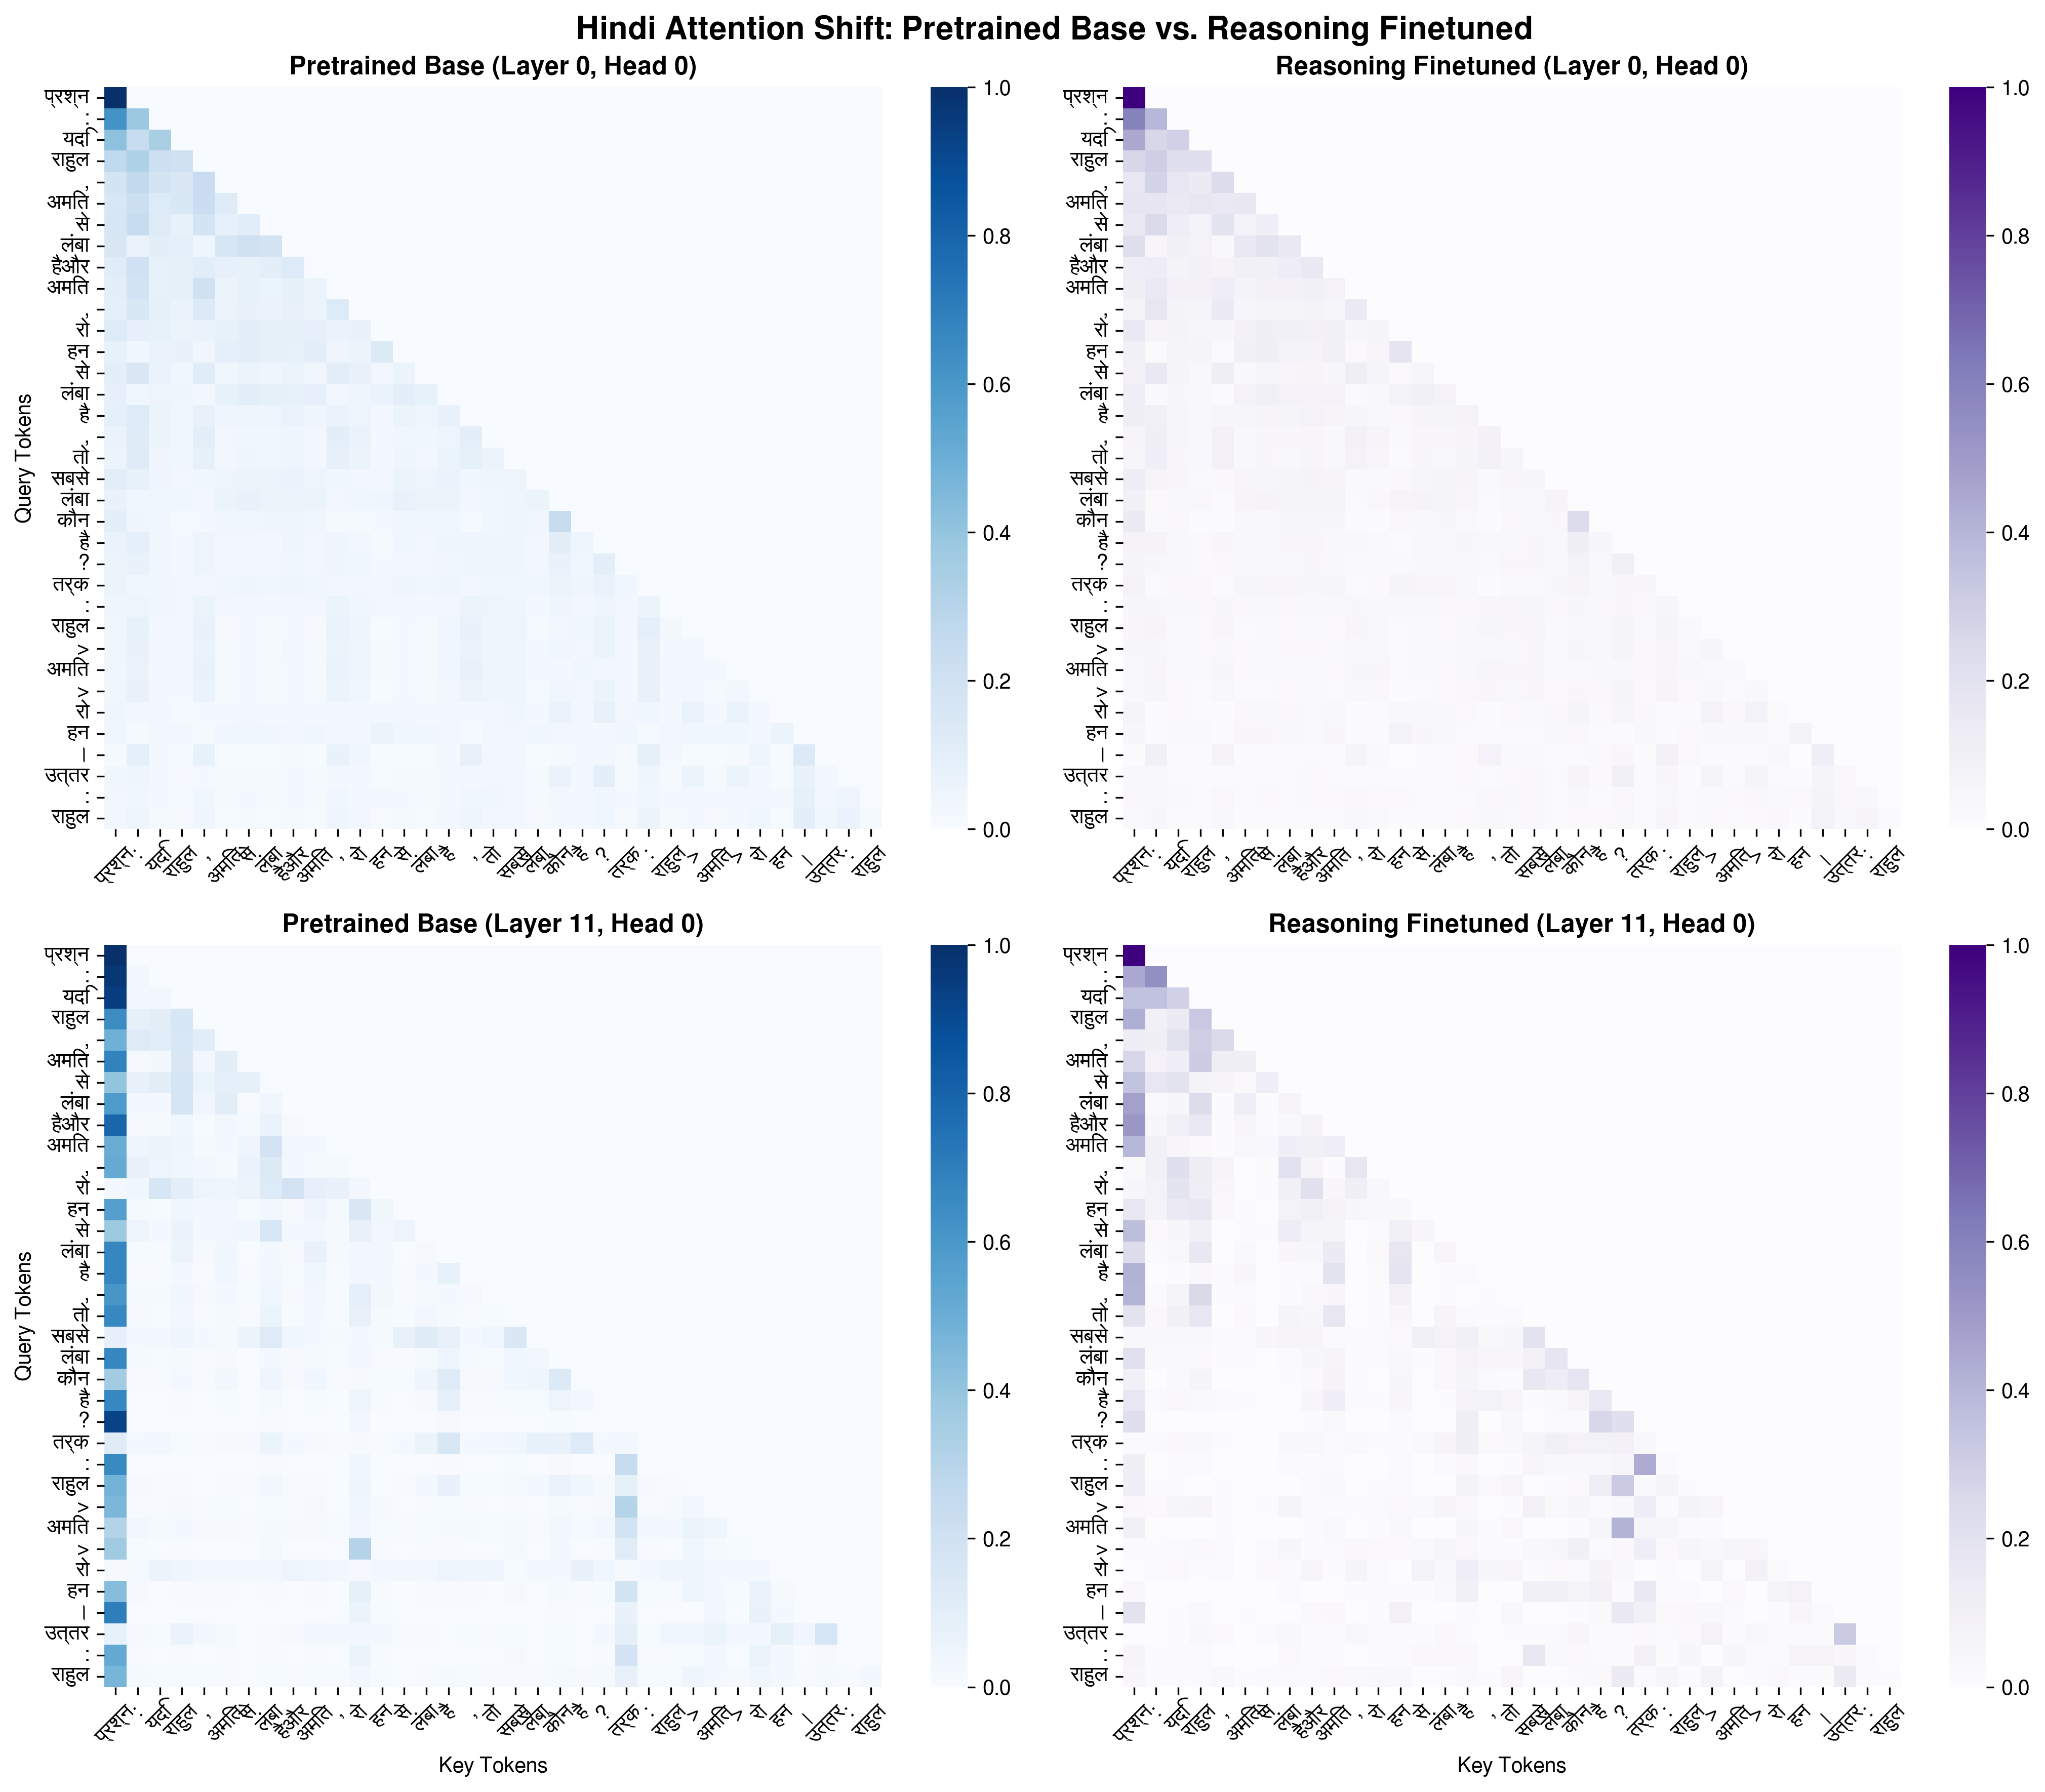

In [10]:
# CELL 9 — POST-FINETUNING ATTENTION SHIFT ANALYSIS & HEATMAPS
attn_script = "/kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/scripts/compare_finetuned_attention.py"
attn_figure = "/kaggle/working/hindi_attention_comparison.png"

print("=" * 65)
print("COMPUTING ATTENTION ENTROPY, DISTANCE & HEATMAPS")
print("=" * 65)

!PYTHONPATH=/kaggle/working python /kaggle/input/datasets/mohdshahidkaleem/phase-3-hindi/phase3_hindi/scripts/compare_finetuned_attention.py \
    --language Hindi \
    --config_file {CONFIG_FILE} \
    --pretrained_checkpoint {PRETRAINED_CKPT} \
    --finetuned_checkpoint {best_ft_ckpt} \
    --tokenizer_model {TOKENIZER_MODEL} \
    --output_figure {attn_figure} \
    --device cuda

from IPython.display import Image, display
if os.path.exists(attn_figure):
    display(Image(attn_figure))
else:
    print("Warning: Attention comparison figure not found.")